# 没有使用path_map

In [ ]:
# 导入大语言模型
from langchain.chat_models import init_chat_model
import os
from dotenv import load_dotenv
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal, Sequence

load_dotenv(override = True)

model = init_chat_model(
    model = "deepseek-flash",
    api_key = os.getenv("DEEPSEEK_API_KEY"),
    base_url = os.getenv("DEEPSEEK_BASE_URL"),
    extra_body = {
        "thinking": {"type": "disabled"}
    }
)

# 定义状态
class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    ci_poem: str
    content_type: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([f"写一首关于{state['topic']}主题的诗"])
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([f"写一个关于{state['topic']}主题的笑话"])
    return {
        "joke": joke
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = model.invoke([f"写一首关于{state['topic']}主题的词"]).content
    return {
        "ci_poem": ci_poem
    }

def route(state: OverAllState) -> Sequence[Literal["node_a", "node_b", "node_c"]]:
    if "诗" in state["content_type"]:
        return ["node_a", "node_c"]
    return ["node_b", "node_c"]

# 构建图
builder = StateGraph(state_schema = OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_conditional_edges(START, route)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "猫咪", "content_type":"诗"})
print(poem_res)

joke_res = graph.invoke({"topic": "猫咪", "content_type": "笑话"})
print(joke_res)

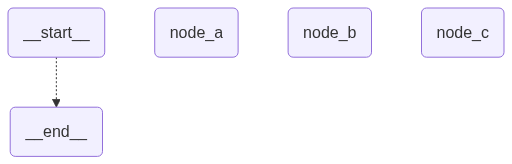

In [15]:
from IPython.display import display
display(graph)

# 使用path_map

In [ ]:
# 导入大语言模型
from langchain.chat_models import init_chat_model
import os
from dotenv import load_dotenv
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

load_dotenv(override = True)

model = init_chat_model(
    model = "deepseek-flash",
    api_key = os.getenv("DEEPSEEK_API_KEY"),
    base_url = os.getenv("DEEPSEEK_BASE_URL"),
    extra_body = {
        "thinking": {"type": "disabled"}
    }
)

# 定义状态
class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    ci_poem: str
    content_type: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([f"写一首关于{state['topic']}主题的诗"])
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([f"写一个关于{state['topic']}主题的笑话"])
    return {
        "joke": joke
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = model.invoke([f"写一首关于{state['topic']}主题的词"]).content
    return {
        "ci_poem": ci_poem
    }

def route(state: OverAllState) -> Sequence[Literal["poem", "joke", "ci_poem"]]:
    if "诗" in state["content_type"]:
        return ["poem", "ci_poem"]
    return ["joke", "ci_poem"]

# 构建图
builder = StateGraph(state_schema = OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_conditional_edges(START, route, path_map = {
    "poem": "node_a",
    "joke":  "node_b",
    "ci_poem": "node_c",
})
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "猫咪", "content_type":"诗"})
print(poem_res)

joke_res = graph.invoke({"topic": "猫咪", "content_type": "笑话"})
print(joke_res)

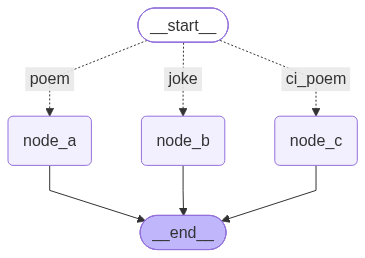

In [17]:
from IPython.display import display
display(graph)